# The benchmark: SHAP, LIME and occlusion across budgets and datasets

Notebook 04 compared SHAP and LIME on IMDB with unequal budgets. This
notebook is the version a paper can cite, and it now asks two questions at
once:

- **Which attribution method is more faithful at a matched budget?** SHAP's
  partition explainer and LIME run at exactly 500 model evaluations per
  review, joined by **occlusion**, the leave one word out baseline both
  methods are approximating shortcuts to. Occlusion has no budget knob, its
  cost is fixed at one prediction per word, which puts it between the two
  budgets on these datasets and makes it the natural reference point.
- **How much budget does a faithful explanation need?** SHAP and LIME also
  run at 50 evaluations, a tenth of the budget. For LIME that means a ridge
  fit on 50 dropout samples over up to 400 word features, for SHAP a
  partition tree that barely gets to split. Comparing each method against its
  own cheap variant measures how quickly explanation power decays with
  budget.

Everything else matches the previous protocol: three datasets, 100 stratified
test reviews each, faithfulness in both directions at cut thresholds of 20 to
80 percent, chunk sizes 1, 4 and 8, all three combinations, each attribution
source paired with its own shuffled control, and every expensive intermediate
cached. The 500 budget sweeps are reused from the existing caches untouched,
only the new sources are measured fresh.

## Configuration

In [1]:
from pathlib import Path

from textfaith.faithfulness import ABSOLUTE_SUM, MAX_ABSOLUTE, SUM_ABSOLUTE

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ARTIFACTS_DIRECTORY = PROJECT_ROOT / "artifacts"

DATASET_DIRECTORIES = {
    "imdb": ARTIFACTS_DIRECTORY / "sample_2000",
    "yelp": ARTIFACTS_DIRECTORY / "yelp_2000",
    "agnews": ARTIFACTS_DIRECTORY / "agnews_2000",
}

OBSERVATION_COUNT = 100
EVALUATION_BUDGETS = [500, 50]
METHOD_BUDGET_PAIRS = [
    ("shap", 500),
    ("lime", 500),
    ("shap", 50),
    ("lime", 50),
    ("occlusion", None),
]
PERCENTILES = [20, 40, 60, 80]
CHUNK_SIZES = [1, 4, 8]
COMBINATIONS = [ABSOLUTE_SUM, SUM_ABSOLUTE, MAX_ABSOLUTE]
RANDOM_SEED = 42

TIDY_RESULTS_PATH = ARTIFACTS_DIRECTORY / "faithfulness_results.parquet"
TIMING_RESULTS_PATH = ARTIFACTS_DIRECTORY / "timing_results.parquet"
METHOD_COMPARISON_PATH = ARTIFACTS_DIRECTORY / "method_comparison.parquet"

print(f"Datasets: {list(DATASET_DIRECTORIES)}")
print(f"Attribution sources: {[pair[0] if pair[1] is None else f'{pair[0]}_{pair[1]}' for pair in METHOD_BUDGET_PAIRS]}")
print(f"Thresholds: {PERCENTILES}, chunk sizes: {CHUNK_SIZES}")

Datasets: ['imdb', 'yelp', 'agnews']
Attribution sources: ['shap_500', 'lime_500', 'shap_50', 'lime_50', 'occlusion']
Thresholds: [20, 40, 60, 80], chunk sizes: [1, 4, 8]


/home/user/projects/shapley/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Run the experiment

One loop, everything load-or-compute, cache filenames encoding the
observation count and budget so no differently configured artifact is ever
silently reused. Occlusion's cache carries no budget suffix because its cost
is not a choice.

The 500 budget sweep records were measured before occlusion and the 50
budget arm existed, under the source names `shap` and `lime`. They are
loaded from their original cache untouched and renamed to `shap_500` and
`lime_500` in memory, so the previously published numbers are preserved
bit for bit while the new sources get their own sweep cache. The percentile
0 invariant runs on the occlusion arrays, the newest path through the
machinery.

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from textfaith.checkpoint import load_predictor
from textfaith.experiment import (
    compute_original_probabilities,
    compute_timed_attributions,
    load_or_compute,
    records_to_tidy_frame,
    sweep_faithfulness,
)
from textfaith.faithfulness import build_word_masker, measure_sufficiency

masker = build_word_masker()
percentile_label = "-".join(str(percentile) for percentile in PERCENTILES)

LEGACY_SOURCE_NAMES = {
    "shap": "shap_500",
    "lime": "lime_500",
    "shap_random": "shap_500_random",
    "lime_random": "lime_500_random",
}

tidy_frames = []
timing_rows = []
original_probability_frames = []

for dataset_name, directory in DATASET_DIRECTORIES.items():
    predict_probabilities, _ = load_predictor(directory)
    test_reviews = pd.read_parquet(directory / "test.parquet")
    sampled_reviews, _ = train_test_split(
        test_reviews,
        train_size=OBSERVATION_COUNT,
        random_state=RANDOM_SEED,
        stratify=test_reviews["label"],
    )
    texts = sampled_reviews["text"].tolist()

    attributions_by_source = {}
    for method_name, budget in METHOD_BUDGET_PAIRS:
        if method_name == "occlusion":
            source_label = "occlusion"
            cache_path = directory / f"occlusion_attributions_{OBSERVATION_COUNT}obs.joblib"
        else:
            source_label = f"{method_name}_{budget}"
            budget_unit = "evals" if method_name == "shap" else "samples"
            cache_path = directory / (
                f"{method_name}_attributions_{OBSERVATION_COUNT}obs_"
                f"{budget}{budget_unit}.joblib"
            )
        was_cached = cache_path.exists()
        payload = load_or_compute(
            cache_path,
            lambda: compute_timed_attributions(
                method_name, predict_probabilities, texts, masker, budget, RANDOM_SEED
            ),
        )
        attributions_by_source[source_label] = payload["attributions"]
        timing_rows.append(
            {
                "dataset": dataset_name,
                "method": method_name,
                "budget": str(budget) if budget is not None else "word_count",
                "wall_seconds": payload["wall_seconds"],
                "prediction_count": payload["prediction_count"],
            }
        )
        for text, attribution in zip(texts, payload["attributions"]):
            assert len(attribution) == len(masker.data_transform(text)[0]), (
                f"{dataset_name}/{source_label}: attribution misaligned with masker words"
            )
        print(
            f"{dataset_name}/{source_label}: "
            f"{'cached' if was_cached else 'computed'}, "
            f"{payload['wall_seconds'] / 60:.1f} minutes, "
            f"{payload['prediction_count']} predictions"
        )

    no_cut_shift = measure_sufficiency(
        predict_probabilities, texts, [0], masker, attributions_by_source["occlusion"]
    )
    assert np.allclose(no_cut_shift, 0, atol=1e-6), "Cutting nothing moved the output"

    legacy_records_path = directory / (
        f"faithfulness_records_{OBSERVATION_COUNT}obs_500budget_{percentile_label}pct.joblib"
    )
    legacy_records = load_or_compute(
        legacy_records_path,
        lambda: sweep_faithfulness(
            predict_probabilities, texts, masker,
            {
                "shap": attributions_by_source["shap_500"],
                "lime": attributions_by_source["lime_500"],
            },
            PERCENTILES, CHUNK_SIZES, COMBINATIONS, RANDOM_SEED,
        ),
    )
    legacy_records = [
        {**record, "source": LEGACY_SOURCE_NAMES[record["source"]]}
        for record in legacy_records
    ]

    extended_records_path = directory / (
        f"faithfulness_records_{OBSERVATION_COUNT}obs_extended_{percentile_label}pct.joblib"
    )
    extended_records = load_or_compute(
        extended_records_path,
        lambda: sweep_faithfulness(
            predict_probabilities, texts, masker,
            {
                label: attributions_by_source[label]
                for label in ["shap_50", "lime_50", "occlusion"]
            },
            PERCENTILES, CHUNK_SIZES, COMBINATIONS, RANDOM_SEED,
        ),
    )

    records = legacy_records + extended_records
    tidy_frames.append(records_to_tidy_frame(records, dataset_name, PERCENTILES))

    originals = load_or_compute(
        directory / f"original_probabilities_{OBSERVATION_COUNT}obs.joblib",
        lambda: compute_original_probabilities(predict_probabilities, texts),
    )
    originals = originals.assign(dataset=dataset_name)
    original_probability_frames.append(originals)
    print(f"{dataset_name}: {len(records)} grid cells measured")

original_probabilities = pd.concat(original_probability_frames, ignore_index=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14682.94it/s]

imdb/shap_500: cached, 28.4 minutes, 50100 predictions
imdb/lime_500: cached, 51.8 minutes, 50100 predictions
imdb/shap_50: cached, 3.2 minutes, 5100 predictions
imdb/lime_50: cached, 7.0 minutes, 5100 predictions
imdb/occlusion: cached, 19.3 minutes, 19266 predictions


imdb: 180 grid cells measured


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

yelp: 180 grid cells measured


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19328.59it/s]

agnews/shap_500: cached, 6.8 minutes, 49268 predictions
agnews/lime_500: cached, 11.9 minutes, 50100 predictions
agnews/shap_50: cached, 0.8 minutes, 5100 predictions
agnews/lime_50: cached, 1.4 minutes, 5100 predictions
agnews/occlusion: cached, 0.7 minutes, 3893 predictions


agnews: 180 grid cells measured


## Speed of execution

Wall clock seconds for computing 100 attributions per source, with the number
of model predictions each actually made. The budget is a cap for SHAP, exact
for LIME, and structural for occlusion, whose count is the corpus word count
plus one original per review.

In [3]:
timing = pd.DataFrame(timing_rows)
timing["seconds_per_review"] = timing["wall_seconds"] / OBSERVATION_COUNT
timing["predictions_per_second"] = (
    timing["prediction_count"] / timing["wall_seconds"]
)
timing = timing.set_index(["dataset", "method", "budget"])
timing.to_parquet(TIMING_RESULTS_PATH)
print(f"Saved {TIMING_RESULTS_PATH}")
timing.round(2)

Saved /home/user/projects/shapley/artifacts/timing_results.parquet


wall_seconds  prediction_count  \
dataset method    budget                                       
imdb    shap      500              1706.40             50100   
        lime      500              3110.36             50100   
        shap      50                192.63              5100   
        lime      50                421.25              5100   
        occlusion word_count       1156.94             19266   
yelp    shap      500               741.58             49780   
        lime      500              2029.74             50100   
        shap      50                111.17              5100   
        lime      50                243.01              5100   
        occlusion word_count        393.86             11833   
agnews  shap      500               405.33             49268   
        lime      500               712.13             50100   
        shap      50                 47.97              5100   
        lime      50                 86.99              5100   
        occlusion word_count         42.52              3893   

                              seconds_per_review  predictions_per_second  
dataset method    budget                                                  
imdb    shap      500                      17.06                   29.36  
        lime      500                      31.10                   16.11  
        shap      50                        1.93                   26.48  
        lime      50                        4.21                   12.11  
        occlusion word_count               11.57                   16.65  
yelp    shap      500                       7.42                   67.13  
        lime      500                      20.30                   24.68  
        shap      50                        1.11                   45.88  
        lime      50                        2.43                   20.99  
        occlusion word_count                3.94                   30.04  
agnews  shap      500                       4.05                  121.55  
        lime      500                       7.12                   70.35  
        shap      50                        0.48                  106.31  
        lime      50                        0.87                   58.63  
        occlusion word_count                0.43                   91.55

## Tidy results for paper statistics

One row per dataset, source, chunk size, combination, direction, percentile
and observation. Sources follow the `method_budget` convention, occlusion's
budget label is `word_count`, and `observation_index` keys the pairing:
every source within a dataset scored the same 100 reviews.

Two derived columns make the shifts interpretable. `original_probability` is
the model's full text predicted class probability, and `relative_shift`
divides the raw shift by it: the share of the model's confidence the cut
moved. Raw shifts are probability points and inherit each head's calibration,
the Yelp head is far more confident than IMDB's, so only the relative form is
comparable across datasets. Within one observation every source shares the
denominator, so the sign of every paired per review difference is unchanged
and the paired verdicts above and below apply to both scales.

In [4]:
from textfaith.experiment import attach_relative_shift

tidy = pd.concat(tidy_frames, ignore_index=True)
tidy = attach_relative_shift(tidy, original_probabilities)

source_count = 2 * len(METHOD_BUDGET_PAIRS)
expected_rows = (
    len(DATASET_DIRECTORIES) * source_count * len(CHUNK_SIZES) * len(COMBINATIONS)
    * 2 * len(PERCENTILES) * OBSERVATION_COUNT
)
assert len(tidy) == expected_rows, (len(tidy), expected_rows)
assert not tidy.isnull().any().any(), "Tidy frame contains nulls"
assert tidy["relative_shift"].between(0, 1).all(), (
    "Relative shifts must lie in [0, 1] because the predicted class starts at or "
    "above one half"
)

tidy.to_parquet(TIDY_RESULTS_PATH, index=False)
print(f"Saved {len(tidy)} rows to {TIDY_RESULTS_PATH}")
tidy.head(8)

Saved 216000 rows to /home/user/projects/shapley/artifacts/faithfulness_results.parquet


,dataset,source,method,budget,is_random,chunk_size,combination,direction,percentile,observation_index,probability_shift,original_probability,relative_shift
0,imdb,shap_500,shap,500,False,1,absolute_sum,sufficiency,20,0,0.062944,0.677858,0.092857
1,imdb,shap_500,shap,500,False,1,absolute_sum,sufficiency,40,0,0.140169,0.677858,0.206782
2,imdb,shap_500,shap,500,False,1,absolute_sum,sufficiency,60,0,0.019401,0.677858,0.028621
3,imdb,shap_500,shap,500,False,1,absolute_sum,sufficiency,80,0,0.062671,0.677858,0.092454
4,imdb,shap_500,shap,500,False,1,absolute_sum,sufficiency,20,1,0.001971,0.720324,0.002736
5,imdb,shap_500,shap,500,False,1,absolute_sum,sufficiency,40,1,0.005962,0.720324,0.008277
6,imdb,shap_500,shap,500,False,1,absolute_sum,sufficiency,60,1,0.000637,0.720324,0.000885
7,imdb,shap_500,shap,500,False,1,absolute_sum,sufficiency,80,1,0.053203,0.720324,0.073859


## Shifts as a percentage of the model's confidence

The same measurements expressed relative to each review's original predicted
class probability, in percent. This is the form a reader can carry across
datasets: cutting the least important text moves the prediction by a few
percent of the model's confidence, cutting the most important text by tens of
percent.

In [5]:
RANKED_SOURCES = ["shap_500", "lime_500", "occlusion", "shap_50", "lime_50"]

relative_table = (
    tidy[
        tidy["source"].isin(RANKED_SOURCES)
        & (tidy["combination"] == ABSOLUTE_SUM)
    ]
    .pivot_table(
        values="relative_shift",
        index=["dataset", "chunk_size"],
        columns=["direction", "source"],
        aggfunc="mean",
    )
    .reindex(
        columns=pd.MultiIndex.from_product(
            [["sufficiency", "comprehensiveness"], RANKED_SOURCES]
        )
    )
)
print(f"Mean shift as percent of original confidence, {ABSOLUTE_SUM}, "
      "averaged over thresholds and observations")
(relative_table * 100).round(1)

Mean shift as percent of original confidence, absolute_sum, averaged over thresholds and observations


sufficiency                                     \
                      shap_500 lime_500 occlusion shap_50 lime_50   
dataset chunk_size                                                  
agnews  1                  5.6      4.4       7.4     6.3     6.4   
        4                  6.9      6.3       9.5     7.1     7.0   
        8                  7.2      7.2       9.1     7.1     6.8   
imdb    1                  7.8     10.6      10.2     8.4    11.2   
        4                  7.7      8.5      11.9     8.9     9.0   
        8                  8.2      8.6      11.5     9.3     9.2   
yelp    1                  4.8      8.5       6.3     3.9    11.7   
        4                  5.0      4.5       6.2     4.4     5.7   
        8                  3.7      3.8       6.3     4.0     4.5   

                   comprehensiveness                                     
                            shap_500 lime_500 occlusion shap_50 lime_50  
dataset chunk_size                                                       
agnews  1                       31.7     28.1      20.3    23.0    20.1  
        4                       20.2     19.7      17.0    20.7    18.7  
        8                       18.0     16.8      14.1    18.3    15.6  
imdb    1                       18.7     20.5      20.0    16.1    19.4  
        4                       17.4     16.1      16.8    15.7    16.3  
        8                       17.0     16.8      15.0    15.9    15.4  
yelp    1                       40.4     35.0      31.2    22.9    29.7  
        4                       29.6     22.7      20.8    21.9    19.6  
        8                       26.3     20.3      16.3    21.5    18.0

## Mean probability shifts

The raw landscape: mean absolute probability shift over all percentiles and
observations, per condition and source. Sufficiency is better when lower,
comprehensiveness when higher, and each source reads against its own
`_random` control.

In [6]:
SOURCE_ORDER = [
    "shap_500", "shap_500_random", "lime_500", "lime_500_random",
    "shap_50", "shap_50_random", "lime_50", "lime_50_random",
    "occlusion", "occlusion_random",
]

mean_table = tidy.pivot_table(
    values="probability_shift",
    index=["dataset", "chunk_size", "combination"],
    columns=["direction", "source"],
    aggfunc="mean",
)
mean_table = mean_table.reindex(
    columns=pd.MultiIndex.from_product(
        [["sufficiency", "comprehensiveness"], SOURCE_ORDER]
    )
)
mean_table.round(4)

sufficiency                           \
                                   shap_500 shap_500_random lime_500   
dataset chunk_size combination                                         
agnews  1          absolute_sum      0.0411          0.1045   0.0319   
                   max_absolute      0.0411          0.1045   0.0319   
                   sum_absolute      0.0411          0.1045   0.0319   
        4          absolute_sum      0.0490          0.0765   0.0447   
                   max_absolute      0.0462          0.0779   0.0493   
                   sum_absolute      0.0443          0.0761   0.0435   
        8          absolute_sum      0.0519          0.0670   0.0508   
                   max_absolute      0.0569          0.0711   0.0555   
                   sum_absolute      0.0483          0.0710   0.0454   
imdb    1          absolute_sum      0.0502          0.1046   0.0704   
                   max_absolute      0.0502          0.1046   0.0704   
                   sum_absolute      0.0502          0.1046   0.0704   
        4          absolute_sum      0.0494          0.0821   0.0545   
                   max_absolute      0.0515          0.0819   0.0503   
                   sum_absolute      0.0492          0.0840   0.0568   
        8          absolute_sum      0.0524          0.0766   0.0552   
                   max_absolute      0.0562          0.0795   0.0536   
                   sum_absolute      0.0526          0.0772   0.0565   
yelp    1          absolute_sum      0.0433          0.1900   0.0778   
                   max_absolute      0.0433          0.1900   0.0778   
                   sum_absolute      0.0433          0.1900   0.0778   
        4          absolute_sum      0.0453          0.0978   0.0402   
                   max_absolute      0.0474          0.1026   0.0470   
                   sum_absolute      0.0496          0.1075   0.0472   
        8          absolute_sum      0.0323          0.0835   0.0334   
                   max_absolute      0.0465          0.0848   0.0387   
                   sum_absolute      0.0442          0.0908   0.0391   

                                                                        \
                                lime_500_random shap_50 shap_50_random   
dataset chunk_size combination                                           
agnews  1          absolute_sum          0.0949  0.0453         0.0887   
                   max_absolute          0.0949  0.0453         0.0887   
                   sum_absolute          0.0949  0.0453         0.0887   
        4          absolute_sum          0.0753  0.0509         0.0873   
                   max_absolute          0.0754  0.0514         0.0698   
                   sum_absolute          0.0747  0.0477         0.0811   
        8          absolute_sum          0.0658  0.0514         0.0736   
                   max_absolute          0.0717  0.0525         0.0535   
                   sum_absolute          0.0670  0.0485         0.0649   
imdb    1          absolute_sum          0.0957  0.0537         0.0959   
                   max_absolute          0.0957  0.0537         0.0959   
                   sum_absolute          0.0957  0.0537         0.0959   
        4          absolute_sum          0.0759  0.0566         0.0820   
                   max_absolute          0.0794  0.0551         0.0762   
                   sum_absolute          0.0786  0.0568         0.0796   
        8          absolute_sum          0.0726  0.0588         0.0790   
                   max_absolute          0.0702  0.0550         0.0650   
                   sum_absolute          0.0726  0.0575         0.0753   
yelp    1          absolute_sum          0.2040  0.0347         0.1645   
                   max_absolute          0.2040  0.0347         0.1645   
                   sum_absolute          0.2040  0.0347         0.1645   
        4          absolute_sum          0.1097  0.0383         0.1075   
                   ma

## Paired statistics at the full budget

The SHAP versus LIME grid at budget 500, unchanged from the previous run
because it derives from the identical cached sweeps. Positive advantages
favor SHAP, the `*_vs_control` columns compare each method against its own
shuffled control, and magnitudes above roughly 2 exceed sampling noise. The
50 budget arm and occlusion are compared in the threshold averaged section
below.

In [7]:
from textfaith.experiment import build_paired_grid

paired_grid = build_paired_grid(tidy, budget=500)
paired_grid.round(2)

sufficiency_shap  sufficiency_lime  \
dataset chunk_size combination                                        
imdb    1          absolute_sum              0.05              0.07   
                   sum_absolute              0.05              0.07   
                   max_absolute              0.05              0.07   
        4          absolute_sum              0.05              0.05   
                   sum_absolute              0.05              0.06   
                   max_absolute              0.05              0.05   
        8          absolute_sum              0.05              0.06   
                   sum_absolute              0.05              0.06   
                   max_absolute              0.06              0.05   
yelp    1          absolute_sum              0.04              0.08   
                   sum_absolute              0.04              0.08   
                   max_absolute              0.04              0.08   
        4          absolute_sum              0.05              0.04   
                   sum_absolute              0.05              0.05   
                   max_absolute              0.05              0.05   
        8          absolute_sum              0.03              0.03   
                   sum_absolute              0.04              0.04   
                   max_absolute              0.05              0.04   
agnews  1          absolute_sum              0.04              0.03   
                   sum_absolute              0.04              0.03   
                   max_absolute              0.04              0.03   
        4          absolute_sum              0.05              0.04   
                   sum_absolute              0.04              0.04   
                   max_absolute              0.05              0.05   
        8          absolute_sum              0.05              0.05   
                   sum_absolute              0.05              0.05   
                   max_absolute              0.06              0.06   

                                 sufficiency_shap_advantage  \
dataset chunk_size combination                                
imdb    1          absolute_sum                        3.10   
                   sum_absolute                        3.10   
                   max_absolute                        3.10   
        4          absolute_sum                        0.73   
                   sum_absolute                        1.16   
                   max_absolute                       -0.39   
        8          absolute_sum                        0.44   
                   sum_absolute                        0.61   
                   max_absolute                       -0.46   
yelp    1          absolute_sum                        2.94   
                   sum_absolute                        2.94   
                   max_absolute                        2.94   
        4          absolute_sum                       -0.58   
                   sum_absolute                       -0.21   
                   max_absolute                        0.34   
        8          absolute_sum                        0.24   
                   sum_absolute                       -0.56   
                   max_absolute                       -0.54   
agnews  1          absolute_sum                       -2.38   
                   sum_absolute                       -2.38   
                   max_absolute                       -2.38   
        4          absolute_sum                       -1.36   
                   sum_absolute                       -0.18   
                   max_absolute                        0.07   
        8          absolute_sum                       -0.04   
                   sum_absolute                        0.21   
                   max_absolute                       -0.45   

                                 sufficiency_shap_vs_control  \
dataset chunk_size combination                                 
imdb    1        

## One number per observation, six comparisons

Averaging the absolute probability shift over the four thresholds gives one
score per review, the area over the perturbation curve. On those scores six
pairwise comparisons run, each with a paired t statistic, a Wilcoxon signed
rank test and a win share, positive numbers always favoring the first named
source:

- `shap_500 vs lime_500` and `shap_50 vs lime_50`, the method question at
  each budget.
- `occlusion vs shap_500` and `occlusion vs lime_500`, whether the fixed cost
  baseline keeps up with the budgeted methods.
- `shap_500 vs shap_50` and `lime_500 vs lime_50`, the budget power question:
  what a tenth of the evaluations costs in faithfulness.

The scores are on the relative scale, shift as a share of the model's
original confidence, so the advantage columns read as percentage points of
confidence and are comparable across datasets. The per review pairing makes
the sign of every difference identical on the raw scale, so the verdicts
transfer. Each comparison is its own family of 54 tests, so the Holm
correction runs per family.

In [8]:
from textfaith.experiment import average_shifts_over_thresholds, compare_methods

SOURCE_PAIRS = [
    ("shap_500", "lime_500"),
    ("shap_50", "lime_50"),
    ("occlusion", "shap_500"),
    ("occlusion", "lime_500"),
    ("shap_500", "shap_50"),
    ("lime_500", "lime_50"),
]

average_shifts = average_shifts_over_thresholds(tidy, value_column="relative_shift")
method_comparison = compare_methods(average_shifts, SOURCE_PAIRS)


def holm_significant(p_values, alpha=0.05):
    order = np.argsort(p_values)
    significant = np.zeros(len(p_values), dtype=bool)
    for rank, index in enumerate(order):
        if p_values[index] > alpha / (len(p_values) - rank):
            break
        significant[index] = True
    return significant


method_comparison["holm_significant"] = (
    method_comparison.groupby(level="comparison")["wilcoxon_p"]
    .transform(lambda p_values: holm_significant(p_values.to_numpy()))
)
method_comparison.to_parquet(METHOD_COMPARISON_PATH)
print(
    f"{len(average_shifts)} observation level scores, "
    f"{len(method_comparison)} comparison rows, saved to {METHOD_COMPARISON_PATH}"
)
display_comparison = method_comparison.copy()
for column in ["average_shift_first", "average_shift_second", "first_advantage"]:
    display_comparison[column] = display_comparison[column] * 100
display_comparison.round(2)

54000 observation level scores, 324 comparison rows, saved to /home/user/projects/shapley/artifacts/method_comparison.parquet


average_shift_first  \
comparison           dataset chunk_size combination  direction                                
shap_500 vs lime_500 agnews  1          absolute_sum comprehensiveness                31.66   
                                                     sufficiency                       5.64   
                                        max_absolute comprehensiveness                31.66   
                                                     sufficiency                       5.64   
                                        sum_absolute comprehensiveness                31.66   
...                                                                                     ...   
lime_500 vs lime_50  yelp    8          absolute_sum sufficiency                       3.80   
                                        max_absolute comprehensiveness                17.72   
                                                     sufficiency                       4.33   
                                        sum_absolute comprehensiveness                17.59   
                                                     sufficiency                       4.44   

                                                                        average_shift_second  \
comparison           dataset chunk_size combination  direction                                 
shap_500 vs lime_500 agnews  1          absolute_sum comprehensiveness                 28.06   
                                                     sufficiency                        4.37   
                                        max_absolute comprehensiveness                 28.06   
                                                     sufficiency                        4.37   
                                        sum_absolute comprehensiveness                 28.06   
...                                                                                      ...   
lime_500 vs lime_50  yelp    8          absolute_sum sufficiency                        4.51   
                                        max_absolute comprehensiveness                 14.03   
                                                     sufficiency                        7.31   
                                        sum_absolute comprehensiveness                 13.93   
                                                     sufficiency                        7.17   

                                                                        first_advantage  \
comparison           dataset chunk_size combination  direction                            
shap_500 vs lime_500 agnews  1          absolute_sum comprehensiveness             3.60   
                                                     sufficiency                  -1.27   
                                        max_absolute comprehensiveness             3.60   
                                                     sufficiency                  -1.27   
                                        sum_absolute comprehensiveness             3.60   
...                                                                                 ...   
lime_500 vs lime_50  yelp    8          absolute_sum sufficiency                   0.71   
                                        max_absolute comprehensiveness             3.69   
                                                     sufficiency                   2.98   
                                        sum_absolute comprehensiveness             3.65   
                                                     sufficiency                   2.73   

                                                                        paired_t  \
comparison           dataset chunk_size combination  direction                     
shap_500 vs lime_500 agnews  1          absolute_sum comprehensiveness      2.44   
                                                     sufficiency           -3.09   
                                        max_absolute comprehensiven

In [9]:
for first, second in SOURCE_PAIRS:
    comparison_name = f"{first} vs {second}"
    subset = method_comparison.loc[comparison_name]
    survivors = subset[subset["holm_significant"]]
    first_wins = int((survivors["first_advantage"] > 0).sum())
    second_wins = int((survivors["first_advantage"] < 0).sum())
    print(
        f"{comparison_name}: {len(survivors)} of {len(subset)} conditions "
        f"significant after Holm, {first_wins} favoring {first}, "
        f"{second_wins} favoring {second}"
    )

shap_500 vs lime_500: 8 of 54 conditions significant after Holm, 5 favoring shap_500, 3 favoring lime_500
shap_50 vs lime_50: 7 of 54 conditions significant after Holm, 7 favoring shap_50, 0 favoring lime_50
occlusion vs shap_500: 17 of 54 conditions significant after Holm, 0 favoring occlusion, 17 favoring shap_500
occlusion vs lime_500: 11 of 54 conditions significant after Holm, 0 favoring occlusion, 11 favoring lime_500
shap_500 vs shap_50: 9 of 54 conditions significant after Holm, 9 favoring shap_500, 0 favoring shap_50
lime_500 vs lime_50: 18 of 54 conditions significant after Holm, 18 favoring lime_500, 0 favoring lime_50


## The comparisons, split by what is held fixed

Two views of the same pairwise statistics. The first holds the evaluation
budget and the chunk size fixed and asks which method wins, aggregating over
datasets and combinations, nine conditions per row. The second holds the
method fixed and asks what the budget buys, aggregating over everything but
the direction, twenty seven conditions per row. Mean advantages are in
percentage points of the model's confidence, positive always favoring the
first named source; the significant counts are Holm corrected within each
comparison family.

In [10]:
comparison_flat = method_comparison.reset_index()
comparison_flat["significant_for_first"] = (
    comparison_flat["holm_significant"] & (comparison_flat["first_advantage"] > 0)
)
comparison_flat["significant_for_second"] = (
    comparison_flat["holm_significant"] & (comparison_flat["first_advantage"] < 0)
)

MATCHED_COMPARISONS = [
    "shap_500 vs lime_500",
    "shap_50 vs lime_50",
    "occlusion vs shap_500",
    "occlusion vs lime_500",
]
matched_view = (
    comparison_flat[comparison_flat["comparison"].isin(MATCHED_COMPARISONS)]
    .groupby(["comparison", "chunk_size", "direction"])
    .agg(
        mean_advantage_percent=(
            "first_advantage", lambda advantages: float(advantages.mean()) * 100
        ),
        significant_for_first=("significant_for_first", "sum"),
        significant_for_second=("significant_for_second", "sum"),
    )
)
print("Methods against methods, budget and chunk size held fixed")
matched_view.round(2)

Methods against methods, budget and chunk size held fixed


mean_advantage_percent  \
comparison            chunk_size direction                                   
occlusion vs lime_500 1          comprehensiveness                   -4.02   
                                 sufficiency                         -0.17   
                      4          comprehensiveness                   -1.90   
                                 sufficiency                         -1.19   
                      8          comprehensiveness                   -1.70   
                                 sufficiency                         -1.16   
occlusion vs shap_500 1          comprehensiveness                   -6.40   
                                 sufficiency                         -1.91   
                      4          comprehensiveness                   -4.52   
                                 sufficiency                         -1.29   
                      8          comprehensiveness                   -3.46   
                                 sufficiency                         -1.05   
shap_50 vs lime_50    1          comprehensiveness                   -2.40   
                                 sufficiency                          3.56   
                      4          comprehensiveness                    2.16   
                                 sufficiency                          0.86   
                      8          comprehensiveness                    2.81   
                                 sufficiency                          1.11   
shap_500 vs lime_500  1          comprehensiveness                    2.39   
                                 sufficiency                          1.74   
                      4          comprehensiveness                    2.62   
                                 sufficiency                          0.09   
                      8          comprehensiveness                    1.77   
                                 sufficiency                         -0.10   

                                                    significant_for_first  \
comparison            chunk_size direction                                  
occlusion vs lime_500 1          comprehensiveness                      0   
                                 sufficiency                            0   
                      4          comprehensiveness                      0   
                                 sufficiency                            0   
                      8          comprehensiveness                      0   
                                 sufficiency                            0   
occlusion vs shap_500 1          comprehensiveness                      0   
                                 sufficiency                            0   
                      4          comprehensiveness                      0   
                                 sufficiency                            0   
                      8          comprehensiveness                      0   
                                 sufficiency                            0   
shap_50 vs lime_50    1          comprehensiveness                      0   
                                 sufficiency                            3   
                      4          comprehensiveness                      1   
                                 sufficiency                            1   
                      8          comprehensiveness                      2   
                                 sufficiency                            0   
shap_500 vs lime_500  1          comprehensiveness                      0   
                                 sufficiency                            0   
                      4          comprehensiveness                      3   
                                 sufficiency                            0   
                      8          comprehensiveness                      2   
                                 sufficiency                            0   

                    

In [11]:
BUDGET_COMPARISONS = ["shap_500 vs shap_50", "lime_500 vs lime_50"]
budget_view = (
    comparison_flat[comparison_flat["comparison"].isin(BUDGET_COMPARISONS)]
    .groupby(["comparison", "direction"])
    .agg(
        mean_advantage_percent=(
            "first_advantage", lambda advantages: float(advantages.mean()) * 100
        ),
        significant_for_first=("significant_for_first", "sum"),
        significant_for_second=("significant_for_second", "sum"),
    )
)
print("Each method against its own budget, both metrics, 27 conditions per row")
budget_view.round(2)

Each method against its own budget, both metrics, 27 conditions per row


mean_advantage_percent  \
comparison          direction                                   
lime_500 vs lime_50 comprehensiveness                    3.09   
                    sufficiency                          1.47   
shap_500 vs shap_50 comprehensiveness                    4.49   
                    sufficiency                          0.20   

                                       significant_for_first  \
comparison          direction                                  
lime_500 vs lime_50 comprehensiveness                      9   
                    sufficiency                            9   
shap_500 vs shap_50 comprehensiveness                      9   
                    sufficiency                            0   

                                       significant_for_second  
comparison          direction                                  
lime_500 vs lime_50 comprehensiveness                       0  
                    sufficiency                             0  
shap_500 vs shap_50 comprehensiveness                       0  
                    sufficiency                             0

## Faithfulness as a function of the evaluation budget

The question this arm answers: how many model evaluations does a faithful
explanation actually need? Each method appears at its two budgets, occlusion
at its fixed per word cost, plotted against the predictions each source
actually made per review. Chunk size 1 under `absolute_sum` is the honest
place to look, it is where the methods differ most and where all three
combinations agree. LIME at 50 samples fits a ridge regression on fewer
samples than most reviews have words, so its cheap arm is expected to
degrade hardest.

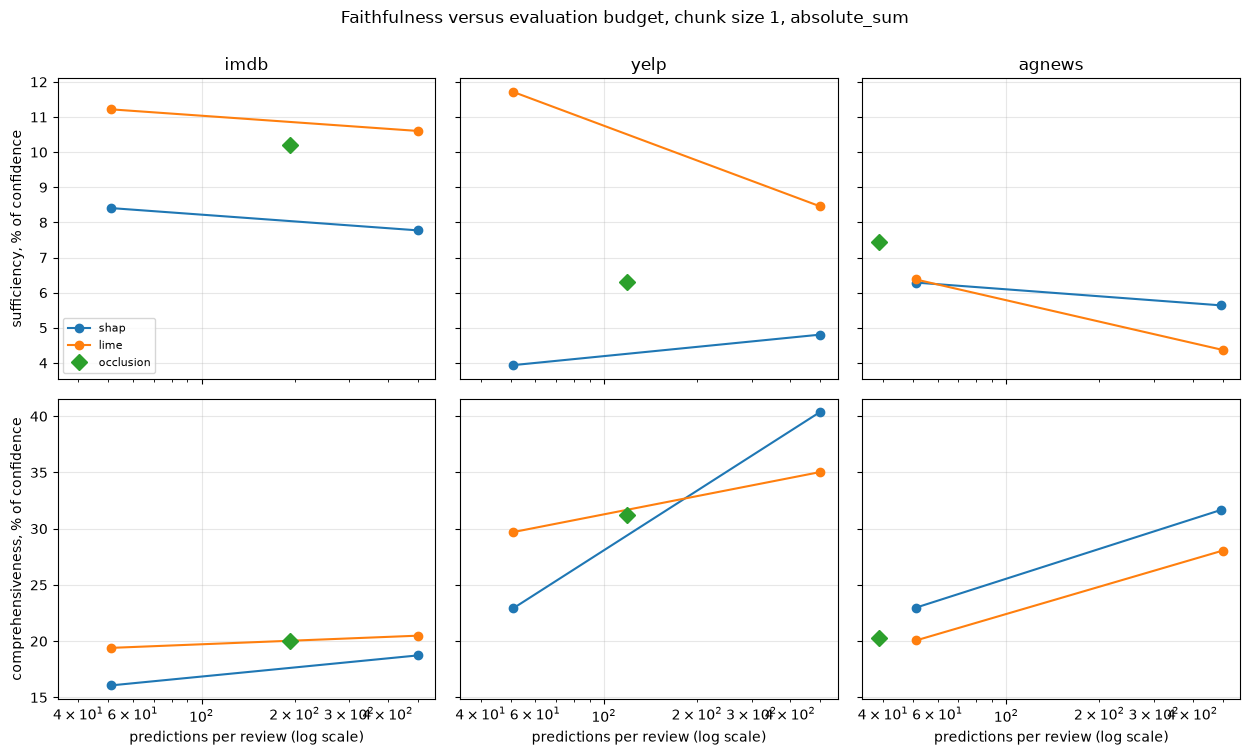

In [12]:
import matplotlib.pyplot as plt

method_colors = {"shap": "C0", "lime": "C1", "occlusion": "C2"}
BUDGET_CHUNK_SIZE = 1
BUDGET_COMBINATION = ABSOLUTE_SUM

predictions_per_review = {
    (row.dataset, row.method, row.budget): row.prediction_count / OBSERVATION_COUNT
    for row in timing.reset_index().itertuples()
}

figure, axes = plt.subplots(
    2, len(DATASET_DIRECTORIES), figsize=(4.2 * len(DATASET_DIRECTORIES), 7.5),
    sharey="row", sharex=True,
)
for column_index, dataset_name in enumerate(DATASET_DIRECTORIES):
    for row_index, direction in enumerate(["sufficiency", "comprehensiveness"]):
        axis = axes[row_index][column_index]
        subset = average_shifts[
            (average_shifts["dataset"] == dataset_name)
            & (~average_shifts["is_random"])
            & (average_shifts["chunk_size"] == BUDGET_CHUNK_SIZE)
            & (average_shifts["combination"] == BUDGET_COMBINATION)
            & (average_shifts["direction"] == direction)
        ]
        means = subset.groupby(["method", "budget"])["average_shift"].mean()
        labeled = row_index == 0 and column_index == 0
        for method in ["shap", "lime"]:
            budgets = ["50", "500"]
            x_values = [
                predictions_per_review[(dataset_name, method, budget)]
                for budget in budgets
            ]
            y_values = [means[(method, budget)] * 100 for budget in budgets]
            axis.plot(
                x_values, y_values, "-o", color=method_colors[method],
                markersize=6, label=method if labeled else None,
            )
        axis.plot(
            [predictions_per_review[(dataset_name, "occlusion", "word_count")]],
            [means[("occlusion", "word_count")] * 100],
            "D", color=method_colors["occlusion"], markersize=8,
            label="occlusion" if labeled else None,
        )
        axis.set_xscale("log")
        axis.grid(alpha=0.3)
        if row_index == 0:
            axis.set_title(dataset_name)
        else:
            axis.set_xlabel("predictions per review (log scale)")

axes[0][0].set_ylabel("sufficiency, % of confidence")
axes[1][0].set_ylabel("comprehensiveness, % of confidence")
axes[0][0].legend(fontsize=8)
figure.suptitle(
    f"Faithfulness versus evaluation budget, chunk size {BUDGET_CHUNK_SIZE}, "
    f"{BUDGET_COMBINATION}",
    y=1.0,
)
figure.tight_layout()
plt.show()

In [13]:
print("Budget power on the threshold averaged scores, Holm corrected per family")
print()
for method in ["shap", "lime"]:
    comparison_name = f"{method}_500 vs {method}_50"
    subset = method_comparison.loc[comparison_name]
    survivors = subset[subset["holm_significant"]]
    full_better = int((survivors["first_advantage"] > 0).sum())
    cheap_better = int((survivors["first_advantage"] < 0).sum())
    print(
        f"{comparison_name}: the full budget is significantly better in "
        f"{full_better} of {len(subset)} conditions, the cheap arm in {cheap_better}"
    )
print()
for comparison_name in ["occlusion vs shap_500", "occlusion vs lime_500"]:
    subset = method_comparison.loc[comparison_name]
    survivors = subset[subset["holm_significant"]]
    print(
        f"{comparison_name}: occlusion significantly better in "
        f"{int((survivors['first_advantage'] > 0).sum())} of {len(subset)}, "
        f"significantly worse in {int((survivors['first_advantage'] < 0).sum())}"
    )

Budget power on the threshold averaged scores, Holm corrected per family

shap_500 vs shap_50: the full budget is significantly better in 9 of 54 conditions, the cheap arm in 0
lime_500 vs lime_50: the full budget is significantly better in 18 of 54 conditions, the cheap arm in 0

occlusion vs shap_500: occlusion significantly better in 0 of 54, significantly worse in 17
occlusion vs lime_500: occlusion significantly better in 0 of 54, significantly worse in 11


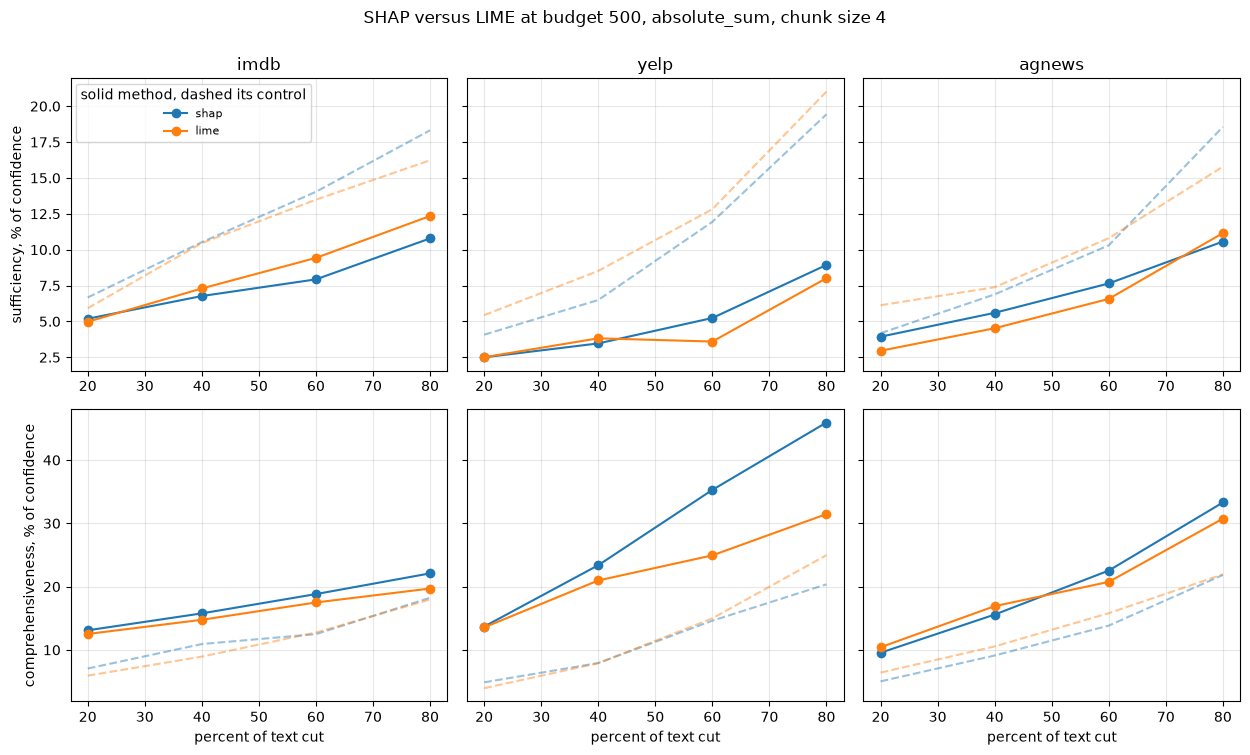

In [14]:
OVERVIEW_CHUNK_SIZE = 4

figure, axes = plt.subplots(
    2, len(DATASET_DIRECTORIES), figsize=(4.2 * len(DATASET_DIRECTORIES), 7.5),
    sharey="row",
)
for column_index, dataset_name in enumerate(DATASET_DIRECTORIES):
    for row_index, direction in enumerate(["sufficiency", "comprehensiveness"]):
        axis = axes[row_index][column_index]
        for method in ["shap", "lime"]:
            for source, style, alpha in [
                (f"{method}_500", "-o", 1.0),
                (f"{method}_500_random", "--", 0.45),
            ]:
                subset = tidy[
                    (tidy["dataset"] == dataset_name)
                    & (tidy["source"] == source)
                    & (tidy["chunk_size"] == OVERVIEW_CHUNK_SIZE)
                    & (tidy["combination"] == ABSOLUTE_SUM)
                    & (tidy["direction"] == direction)
                ]
                means = subset.groupby("percentile")["relative_shift"].mean() * 100
                axis.plot(
                    means.index, means.to_numpy(), style,
                    color=method_colors[method], alpha=alpha,
                    label=method if source == f"{method}_500" else None,
                )
        if row_index == 0:
            axis.set_title(dataset_name)
        else:
            axis.set_xlabel("percent of text cut")
        axis.grid(alpha=0.3)

axes[0][0].set_ylabel("sufficiency, % of confidence")
axes[1][0].set_ylabel("comprehensiveness, % of confidence")
axes[0][0].legend(title="solid method, dashed its control", fontsize=8)
figure.suptitle(
    f"SHAP versus LIME at budget 500, {ABSOLUTE_SUM}, chunk size {OVERVIEW_CHUNK_SIZE}",
    y=1.0,
)
figure.tight_layout()
plt.show()

## Reading of the result

Verdicts computed from the tables, not asserted. Wins require the paired
advantage or the Holm corrected Wilcoxon to clear the noise threshold.

In [15]:
print("Head to head cells with |advantage| > 2 at budget 500, per dataset (9 cells each)")
print()
for dataset_name in DATASET_DIRECTORIES:
    subset = paired_grid.loc[dataset_name]
    for direction in ["sufficiency", "comprehensiveness"]:
        advantages = subset[f"{direction}_shap_advantage"]
        shap_wins = int((advantages > 2).sum())
        lime_wins = int((advantages < -2).sum())
        print(
            f"{dataset_name} {direction}: SHAP {shap_wins}, LIME {lime_wins}, "
            f"within noise {len(advantages) - shap_wins - lime_wins}"
        )
    print()

timing_flat = timing.reset_index()
for method, budget in [
    ("shap", "500"), ("lime", "500"), ("shap", "50"), ("lime", "50"),
    ("occlusion", "word_count"),
]:
    seconds = timing_flat[
        (timing_flat["method"] == method) & (timing_flat["budget"] == budget)
    ]["wall_seconds"].sum()
    print(
        f"{method} at budget {budget}: {seconds / 60:.1f} minutes "
        f"across the three datasets"
    )

Head to head cells with |advantage| > 2 at budget 500, per dataset (9 cells each)

imdb sufficiency: SHAP 3, LIME 0, within noise 6
imdb comprehensiveness: SHAP 0, LIME 0, within noise 9

yelp sufficiency: SHAP 3, LIME 0, within noise 6
yelp comprehensiveness: SHAP 4, LIME 0, within noise 5

agnews sufficiency: SHAP 0, LIME 3, within noise 6
agnews comprehensiveness: SHAP 0, LIME 0, within noise 9

shap at budget 500: 47.6 minutes across the three datasets
lime at budget 500: 97.5 minutes across the three datasets
shap at budget 50: 5.9 minutes across the three datasets
lime at budget 50: 12.5 minutes across the three datasets
occlusion at budget word_count: 26.6 minutes across the three datasets
